In [1]:
# ============================================================
# MultiModalCancerTherapy
# 01 - Clinical Data Preprocessing
# ============================================================

from pathlib import Path
import pandas as pd
import numpy as np

# Project root
PROJECT_ROOT = Path.cwd().parent

# Clinical dataset path
CLINICAL_DATA_PATH = (
    PROJECT_ROOT
    / "datasets"
    / "raw"
    / "clinical"
    / "Thyroid Disease Data"
    / "thyroidDF.csv"
)

print("Project Root:")
print(PROJECT_ROOT)

print("\nClinical Dataset Path:")
print(CLINICAL_DATA_PATH)

print("\nDataset Exists:", CLINICAL_DATA_PATH.exists())

Project Root:
D:\MultiModalCancerTherapy_Structure\MultiModalCancerTherapy_Structure

Clinical Dataset Path:
D:\MultiModalCancerTherapy_Structure\MultiModalCancerTherapy_Structure\datasets\raw\clinical\Thyroid Disease Data\thyroidDF.csv

Dataset Exists: True


In [2]:
# ============================================================
# Load Clinical Dataset
# ============================================================

if not CLINICAL_DATA_PATH.exists():
    raise FileNotFoundError(
        f"Clinical dataset not found:\n{CLINICAL_DATA_PATH}"
    )

df = pd.read_csv(CLINICAL_DATA_PATH)

print("Dataset loaded successfully.")
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

Dataset loaded successfully.
Rows: 9172
Columns: 31


In [3]:
# Display first 10 records

df.head(10)

,age,sex,on_thyroxine,query_on_thyroxine,on_antithyroid_meds,sick,pregnant,thyroid_surgery,I131_treatment,query_hypothyroid,...,TT4,T4U_measured,T4U,FTI_measured,FTI,TBG_measured,TBG,referral_source,target,patient_id
0,29,F,f,f,f,f,f,f,f,t,...,NaN,f,NaN,f,NaN,f,NaN,other,-,840801013
1,29,F,f,f,f,f,f,f,f,f,...,128.0,f,NaN,f,NaN,f,NaN,other,-,840801014
2,41,F,f,f,f,f,f,f,f,f,...,NaN,f,NaN,f,NaN,t,11.0,other,-,840801042
3,36,F,f,f,f,f,f,f,f,f,...,NaN,f,NaN,f,NaN,t,26.0,other,-,840803046
4,32,F,f,f,f,f,f,f,f,f,...,NaN,f,NaN,f,NaN,t,36.0,other,S,840803047
5,60,F,f,f,f,f,f,f,f,f,...,NaN,f,NaN,f,NaN,t,26.0,other,-,840803048
6,77,F,f,f,f,f,f,f,f,f,...,NaN,f,NaN,f,NaN,t,21.0,other,-,840803068
7,28,F,f,f,f,f,f,f,f,f,...,116.0,f,NaN,f,NaN,f,NaN,SVI,-,840807019
8,28,F,f,f,f,f,f,f,f,f,...,76.0,f,NaN,f,NaN,f,NaN,other,-,840808060
9,28,F,f,f,f,f,f,f,f,f,...,83.0,f,NaN,f,NaN,f,NaN,other,-,840808073


In [4]:
# ============================================================
# Dataset Information
# ============================================================

print("Column Names:\n")

for i, column in enumerate(df.columns, start=1):
    print(f"{i}. {column}")

print("\nDataset Info:")
df.info()

Column Names:

1. age
2. sex
3. on_thyroxine
4. query_on_thyroxine
5. on_antithyroid_meds
6. sick
7. pregnant
8. thyroid_surgery
9. I131_treatment
10. query_hypothyroid
11. query_hyperthyroid
12. lithium
13. goitre
14. tumor
15. hypopituitary
16. psych
17. TSH_measured
18. TSH
19. T3_measured
20. T3
21. TT4_measured
22. TT4
23. T4U_measured
24. T4U
25. FTI_measured
26. FTI
27. TBG_measured
28. TBG
29. referral_source
30. target
31. patient_id

Dataset Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9172 entries, 0 to 9171
Data columns (total 31 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   age                  9172 non-null   int64  
 1   sex                  8865 non-null   object 
 2   on_thyroxine         9172 non-null   object 
 3   query_on_thyroxine   9172 non-null   object 
 4   on_antithyroid_meds  9172 non-null   object 
 5   sick                 9172 non-null   object 
 6   pregnant             9172 

In [5]:
# ============================================================
# Missing Value Analysis
# ============================================================

missing_count = df.isnull().sum()

missing_percentage = (
    df.isnull().mean() * 100
).round(2)

missing_summary = pd.DataFrame({
    "Missing_Count": missing_count,
    "Missing_Percentage": missing_percentage
})

missing_summary = missing_summary[
    missing_summary["Missing_Count"] > 0
].sort_values(
    by="Missing_Count",
    ascending=False
)

missing_summary

,Missing_Count,Missing_Percentage
TBG,8823,96.19
T3,2604,28.39
TSH,842,9.18
T4U,809,8.82
FTI,802,8.74
TT4,442,4.82
sex,307,3.35


In [6]:
# ============================================================
# Duplicate Analysis
# ============================================================

duplicate_count = df.duplicated().sum()

print("Duplicate rows:", duplicate_count)

Duplicate rows: 0


In [7]:
# ============================================================
# Statistical Summary
# ============================================================

df.describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
age,9172.0,NaN,NaN,NaN,73.555822,1183.976718,1.0,37.0,55.0,68.0,65526.0
sex,8865,2,F,6073,NaN,NaN,NaN,NaN,NaN,NaN,NaN
on_thyroxine,9172,2,f,7932,NaN,NaN,NaN,NaN,NaN,NaN,NaN
query_on_thyroxine,9172,2,f,9019,NaN,NaN,NaN,NaN,NaN,NaN,NaN
on_antithyroid_meds,9172,2,f,9056,NaN,NaN,NaN,NaN,NaN,NaN,NaN
sick,9172,2,f,8828,NaN,NaN,NaN,NaN,NaN,NaN,NaN
pregnant,9172,2,f,9065,NaN,NaN,NaN,NaN,NaN,NaN,NaN
thyroid_surgery,9172,2,f,9038,NaN,NaN,NaN,NaN,NaN,NaN,NaN
I131_treatment,9172,2,f,9003,NaN,NaN,NaN,NaN,NaN,NaN,NaN
query_hypothyroid,9172,2,f,8542,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [8]:
from pathlib import Path
import pandas as pd
import numpy as np

# Project root
PROJECT_ROOT = Path.cwd().parent

# Clinical dataset path
CLINICAL_DATA_PATH = (
    PROJECT_ROOT
    / "datasets"
    / "raw"
    / "clinical"
    / "Thyroid Disease Data"
    / "thyroidDF.csv"
)

print("Project Root:")
print(PROJECT_ROOT)

print("\nClinical Dataset Path:")
print(CLINICAL_DATA_PATH)

print("\nDataset Exists:", CLINICAL_DATA_PATH.exists())

Project Root:
D:\MultiModalCancerTherapy_Structure\MultiModalCancerTherapy_Structure

Clinical Dataset Path:
D:\MultiModalCancerTherapy_Structure\MultiModalCancerTherapy_Structure\datasets\raw\clinical\Thyroid Disease Data\thyroidDF.csv

Dataset Exists: True


In [9]:
# ============================================================
# Step 2 - Load Clinical Dataset
# ============================================================

if not CLINICAL_DATA_PATH.exists():
    raise FileNotFoundError(
        f"Clinical dataset not found:\n{CLINICAL_DATA_PATH}"
    )

df = pd.read_csv(CLINICAL_DATA_PATH)

print("Dataset loaded successfully.")
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

Dataset loaded successfully.
Rows: 9172
Columns: 31


In [10]:
# ============================================================
# Step 3 - Preview Clinical Dataset
# ============================================================

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)

df.head(10)

,age,sex,on_thyroxine,query_on_thyroxine,on_antithyroid_meds,sick,pregnant,thyroid_surgery,I131_treatment,query_hypothyroid,query_hyperthyroid,lithium,goitre,tumor,hypopituitary,psych,TSH_measured,TSH,T3_measured,T3,TT4_measured,TT4,T4U_measured,T4U,FTI_measured,FTI,TBG_measured,TBG,referral_source,target,patient_id
0,29,F,f,f,f,f,f,f,f,t,f,f,f,f,f,f,t,0.3,f,NaN,f,NaN,f,NaN,f,NaN,f,NaN,other,-,840801013
1,29,F,f,f,f,f,f,f,f,f,f,f,f,f,f,f,t,1.6,t,1.9,t,128.0,f,NaN,f,NaN,f,NaN,other,-,840801014
2,41,F,f,f,f,f,f,f,f,f,t,f,f,f,f,f,f,NaN,f,NaN,f,NaN,f,NaN,f,NaN,t,11.0,other,-,840801042
3,36,F,f,f,f,f,f,f,f,f,f,f,f,f,f,f,f,NaN,f,NaN,f,NaN,f,NaN,f,NaN,t,26.0,other,-,840803046
4,32,F,f,f,f,f,f,f,f,f,f,f,f,f,f,f,f,NaN,f,NaN,f,NaN,f,NaN,f,NaN,t,36.0,other,S,840803047
5,60,F,f,f,f,f,f,f,f,f,f,f,f,f,f,f,f,NaN,f,NaN,f,NaN,f,NaN,f,NaN,t,26.0,other,-,840803048
6,77,F,f,f,f,f,f,f,f,f,f,f,f,f,f,f,f,NaN,f,NaN,f,NaN,f,NaN,f,NaN,t,21.0,other,-,840803068
7,28,F,f,f,f,f,f,f,f,f,f,f,f,f,f,f,t,0.7,t,2.6,t,116.0,f,NaN,f,NaN,f,NaN,SVI,-,840807019
8,28,F,f,f,f,f,f,f,f,f,f,f,f,f,f,f,t,1.2,t,1.8,t,76.0,f,NaN,f,NaN,f,NaN,other,-,840808060
9,28,F,f,f,f,f,f,f,f,f,f,f,f,f,f,f,t,1.9,t,1.7,t,83.0,f,NaN,f,NaN,f,NaN,other,-,840808073


In [11]:
# ============================================================
# Step 4 - Column Names and Data Types
# ============================================================

print("Total Columns:", len(df.columns))
print("\nColumn Information:\n")

column_info = pd.DataFrame({
    "Column": df.columns,
    "Data_Type": df.dtypes.astype(str),
    "Missing_Count": df.isnull().sum(),
    "Missing_Percentage": (df.isnull().mean() * 100).round(2)
})

column_info

Total Columns: 31

Column Information:



,Column,Data_Type,Missing_Count,Missing_Percentage
age,age,int64,0,0.00
sex,sex,object,307,3.35
on_thyroxine,on_thyroxine,object,0,0.00
query_on_thyroxine,query_on_thyroxine,object,0,0.00
on_antithyroid_meds,on_antithyroid_meds,object,0,0.00
sick,sick,object,0,0.00
pregnant,pregnant,object,0,0.00
thyroid_surgery,thyroid_surgery,object,0,0.00
I131_treatment,I131_treatment,object,0,0.00
query_hypothyroid,query_hypothyroid,object,0,0.00


In [12]:
# ============================================================
# Step 4 - Column Names and Data Types
# ============================================================

print("Total Columns:", len(df.columns))
print("\nColumn Information:\n")

column_info = pd.DataFrame({
    "Column": df.columns,
    "Data_Type": df.dtypes.astype(str),
    "Missing_Count": df.isnull().sum(),
    "Missing_Percentage": (df.isnull().mean() * 100).round(2)
})

column_info

Total Columns: 31

Column Information:



,Column,Data_Type,Missing_Count,Missing_Percentage
age,age,int64,0,0.00
sex,sex,object,307,3.35
on_thyroxine,on_thyroxine,object,0,0.00
query_on_thyroxine,query_on_thyroxine,object,0,0.00
on_antithyroid_meds,on_antithyroid_meds,object,0,0.00
sick,sick,object,0,0.00
pregnant,pregnant,object,0,0.00
thyroid_surgery,thyroid_surgery,object,0,0.00
I131_treatment,I131_treatment,object,0,0.00
query_hypothyroid,query_hypothyroid,object,0,0.00


In [13]:
# ============================================================
# Step 5 - Target Distribution Analysis
# ============================================================

print("Target Value Counts:")
print(df["target"].value_counts())

print("\nTarget Value Percentages:")
print(
    (df["target"].value_counts(normalize=True) * 100)
    .round(2)
)

Target Value Counts:
target
-      6771
K       436
G       359
I       346
F       233
R       196
A       147
L       115
M       111
N       110
S        85
GK       49
AK       46
J        30
B        21
MK       16
O        14
Q        14
C|I      12
KJ       11
GI       10
H|K       8
D         8
FK        6
C         6
P         5
MI        2
LJ        1
GKJ       1
OI        1
D|R       1
E         1
Name: count, dtype: int64

Target Value Percentages:
target
-      73.82
K       4.75
G       3.91
I       3.77
F       2.54
R       2.14
A       1.60
L       1.25
M       1.21
N       1.20
S       0.93
GK      0.53
AK      0.50
J       0.33
B       0.23
MK      0.17
O       0.15
Q       0.15
C|I     0.13
KJ      0.12
GI      0.11
H|K     0.09
D       0.09
FK      0.07
C       0.07
P       0.05
MI      0.02
LJ      0.01
GKJ     0.01
OI      0.01
D|R     0.01
E       0.01
Name: proportion, dtype: float64


In [14]:
# ============================================================
# Step 6 - Target Validity Analysis
# ============================================================

# Count records with no recorded diagnosis
no_diagnosis = (df["target"] == "-").sum()

# Count records with a recorded diagnosis
diagnosed = (df["target"] != "-").sum()

print("Records with target '-':", no_diagnosis)
print("Records with diagnosis:", diagnosed)

print("\nDiagnosis percentage:")
print(round((diagnosed / len(df)) * 100, 2), "%")

print("\nUnique diagnosis codes:")
diagnosis_codes = df.loc[df["target"] != "-", "target"].unique()

for code in sorted(diagnosis_codes):
    print(code)

Records with target '-': 6771
Records with diagnosis: 2401

Diagnosis percentage:
26.18 %

Unique diagnosis codes:
A
AK
B
C
C|I
D
D|R
E
F
FK
G
GI
GK
GKJ
H|K
I
J
K
KJ
L
LJ
M
MI
MK
N
O
OI
P
Q
R
S


In [15]:
# ============================================================
# Step 7 - Create Diagnosis Dataset
# ============================================================

# Keep only records having a recorded target
diagnosis_df = df[df["target"] != "-"].copy()

print("Original dataset shape:")
print(df.shape)

print("\nDiagnosis dataset shape:")
print(diagnosis_df.shape)

print("\nDiagnosis class distribution:")
print(diagnosis_df["target"].value_counts())

print("\nTop 10 diagnosis classes:")
print(diagnosis_df["target"].value_counts().head(10))

Original dataset shape:
(9172, 31)

Diagnosis dataset shape:
(2401, 31)

Diagnosis class distribution:
target
K      436
G      359
I      346
F      233
R      196
A      147
L      115
M      111
N      110
S       85
GK      49
AK      46
J       30
B       21
MK      16
O       14
Q       14
C|I     12
KJ      11
GI      10
H|K      8
D        8
FK       6
C        6
P        5
MI       2
LJ       1
GKJ      1
OI       1
D|R      1
E        1
Name: count, dtype: int64

Top 10 diagnosis classes:
target
K    436
G    359
I    346
F    233
R    196
A    147
L    115
M    111
N    110
S     85
Name: count, dtype: int64


In [16]:
# ============================================================
# Step 8 - Check Categorical Feature Values
# ============================================================

categorical_columns = diagnosis_df.select_dtypes(
    include=["object"]
).columns.tolist()

print("Categorical columns:\n")
print(categorical_columns)

print("\nUnique values in each categorical column:\n")

for column in categorical_columns:
    print(f"\n--- {column} ---")
    print(diagnosis_df[column].value_counts(dropna=False).head(20))

Categorical columns:

['sex', 'on_thyroxine', 'query_on_thyroxine', 'on_antithyroid_meds', 'sick', 'pregnant', 'thyroid_surgery', 'I131_treatment', 'query_hypothyroid', 'query_hyperthyroid', 'lithium', 'goitre', 'tumor', 'hypopituitary', 'psych', 'TSH_measured', 'T3_measured', 'TT4_measured', 'T4U_measured', 'FTI_measured', 'TBG_measured', 'referral_source', 'target']

Unique values in each categorical column:


--- sex ---
sex
F      1740
M       566
NaN      95
Name: count, dtype: int64

--- on_thyroxine ---
on_thyroxine
f    1979
t     422
Name: count, dtype: int64

--- query_on_thyroxine ---
query_on_thyroxine
f    2361
t      40
Name: count, dtype: int64

--- on_antithyroid_meds ---
on_antithyroid_meds
f    2366
t      35
Name: count, dtype: int64

--- sick ---
sick
f    2319
t      82
Name: count, dtype: int64

--- pregnant ---
pregnant
f    2324
t      77
Name: count, dtype: int64

--- thyroid_surgery ---
thyroid_surgery
f    2369
t      32
Name: count, dtype: int64

--- I131_tr

In [17]:
# ============================================================
# Step 9 - Numerical Feature Analysis
# ============================================================

numeric_columns = diagnosis_df.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

print("Numerical columns:")
print(numeric_columns)

print("\nNumerical Summary:")
display(
    diagnosis_df[numeric_columns].describe().T
)

print("\nMissing values in numerical columns:")
numeric_missing = pd.DataFrame({
    "Missing_Count": diagnosis_df[numeric_columns].isnull().sum(),
    "Missing_Percentage": (
        diagnosis_df[numeric_columns].isnull().mean() * 100
    ).round(2)
})

display(numeric_missing)

Numerical columns:
['age', 'TSH', 'T3', 'TT4', 'T4U', 'FTI', 'TBG', 'patient_id']

Numerical Summary:


,count,mean,std,min,25%,50%,75%,max
age,2401.0,5.298209e+01,1.973343e+01,1.000000e+00,3.600000e+01,5.600000e+01,7.000000e+01,9.500000e+01
TSH,2248.0,1.475276e+01,4.495469e+01,5.000000e-03,2.500000e-01,2.100000e+00,9.099999e+00,5.300000e+02
T3,1806.0,1.920078e+00,1.424901e+00,5.000000e-02,1.000000e+00,1.600000e+00,2.500000e+00,1.800000e+01
TT4,2304.0,1.163484e+02,5.963286e+01,2.000000e+00,7.600000e+01,1.090000e+02,1.570000e+02,6.000000e+02
T4U,2218.0,1.007795e+00,2.812843e-01,1.700000e-01,8.400000e-01,9.600000e-01,1.110000e+00,2.330000e+00
FTI,2219.0,1.211260e+02,7.009178e+01,1.400000e+00,8.300000e+01,1.090000e+02,1.580000e+02,8.810000e+02
TBG,98.0,4.771735e+01,3.239875e+01,9.299999e+00,3.200000e+01,3.600000e+01,4.675000e+01,2.000000e+02
patient_id,2401.0,8.528920e+08,7.595916e+06,8.408030e+08,8.504100e+08,8.510041e+08,8.607100e+08,8.701190e+08



Missing values in numerical columns:


,Missing_Count,Missing_Percentage
age,0,0.00
TSH,153,6.37
T3,595,24.78
TT4,97,4.04
T4U,183,7.62
FTI,182,7.58
TBG,2303,95.92
patient_id,0,0.00


In [18]:
# ============================================================
# Step 10 - Prepare Features and Target
# ============================================================

# Columns that should NOT be used for model training
columns_to_drop = [
    "patient_id",   # Identifier only
    "TBG"           # 95.92% missing values
]

# Create feature dataset
X = diagnosis_df.drop(
    columns=columns_to_drop + ["target"]
)

# Target
y = diagnosis_df["target"].copy()

print("Feature dataset shape:", X.shape)
print("Target shape:", y.shape)

print("\nFeatures:")
print(X.columns.tolist())

print("\nTarget classes:", y.nunique())

Feature dataset shape: (2401, 28)
Target shape: (2401,)

Features:
['age', 'sex', 'on_thyroxine', 'query_on_thyroxine', 'on_antithyroid_meds', 'sick', 'pregnant', 'thyroid_surgery', 'I131_treatment', 'query_hypothyroid', 'query_hyperthyroid', 'lithium', 'goitre', 'tumor', 'hypopituitary', 'psych', 'TSH_measured', 'TSH', 'T3_measured', 'T3', 'TT4_measured', 'TT4', 'T4U_measured', 'T4U', 'FTI_measured', 'FTI', 'TBG_measured', 'referral_source']

Target classes: 31


In [19]:
# ============================================================
# Step 11 - Clinical Data Preprocessing
# ============================================================

from sklearn.preprocessing import LabelEncoder
from sklearn.impute import SimpleImputer

# Make a copy
X_prepared = X.copy()

# ------------------------------------------------------------
# 1. Convert binary t/f columns to 1/0
# ------------------------------------------------------------

binary_columns = [
    "on_thyroxine",
    "query_on_thyroxine",
    "on_antithyroid_meds",
    "sick",
    "pregnant",
    "thyroid_surgery",
    "I131_treatment",
    "query_hypothyroid",
    "query_hyperthyroid",
    "lithium",
    "goitre",
    "tumor",
    "hypopituitary",
    "psych",
    "TSH_measured",
    "T3_measured",
    "TT4_measured",
    "T4U_measured",
    "FTI_measured",
    "TBG_measured"
]

for column in binary_columns:
    X_prepared[column] = (
        X_prepared[column]
        .map({"t": 1, "f": 0})
        .astype("float")
    )

# ------------------------------------------------------------
# 2. Encode sex
# ------------------------------------------------------------

X_prepared["sex"] = (
    X_prepared["sex"]
    .map({"M": 1, "F": 0})
)

# ------------------------------------------------------------
# 3. Encode referral source
# ------------------------------------------------------------

referral_encoder = LabelEncoder()

X_prepared["referral_source"] = (
    referral_encoder.fit_transform(
        X_prepared["referral_source"]
    )
)

# ------------------------------------------------------------
# 4. Fill missing numerical values using median
# ------------------------------------------------------------

numeric_features = [
    "age",
    "TSH",
    "T3",
    "TT4",
    "T4U",
    "FTI"
]

numeric_imputer = SimpleImputer(strategy="median")

X_prepared[numeric_features] = (
    numeric_imputer.fit_transform(
        X_prepared[numeric_features]
    )
)

# ------------------------------------------------------------
# 5. Encode target classes
# ------------------------------------------------------------

target_encoder = LabelEncoder()

y_encoded = target_encoder.fit_transform(y)

# ------------------------------------------------------------
# Results
# ------------------------------------------------------------

print("Preprocessing completed successfully.")

print("\nPrepared feature shape:")
print(X_prepared.shape)

print("\nTarget shape:")
print(y_encoded.shape)

print("\nTarget classes:")
print(list(target_encoder.classes_))

print("\nRemaining missing values:")
print(X_prepared.isnull().sum().sum())

Preprocessing completed successfully.

Prepared feature shape:
(2401, 28)

Target shape:
(2401,)

Target classes:
['A', 'AK', 'B', 'C', 'C|I', 'D', 'D|R', 'E', 'F', 'FK', 'G', 'GI', 'GK', 'GKJ', 'H|K', 'I', 'J', 'K', 'KJ', 'L', 'LJ', 'M', 'MI', 'MK', 'N', 'O', 'OI', 'P', 'Q', 'R', 'S']

Remaining missing values:
95


In [20]:
# ============================================================
# Step 12 - Find Remaining Missing Values
# ============================================================

remaining_missing = X_prepared.isnull().sum()

remaining_missing = remaining_missing[
    remaining_missing > 0
].sort_values(ascending=False)

print("Columns with remaining missing values:\n")
print(remaining_missing)

Columns with remaining missing values:

sex    95
dtype: int64


In [21]:
# ============================================================
# Step 13 - Handle Missing Sex Values
# ============================================================

sex_imputer = SimpleImputer(strategy="most_frequent")

X_prepared[["sex"]] = sex_imputer.fit_transform(
    X_prepared[["sex"]]
)

print("Missing values after sex imputation:")

remaining_missing = X_prepared.isnull().sum()

remaining_missing = remaining_missing[
    remaining_missing > 0
]

print(remaining_missing)

print("\nTotal remaining missing values:")
print(X_prepared.isnull().sum().sum())

Missing values after sex imputation:
Series([], dtype: int64)

Total remaining missing values:
0


In [23]:
# ============================================================
# Step 14A - Check Rare Target Classes
# ============================================================

target_counts = diagnosis_df["target"].value_counts().sort_values()

print("Target classes with their sample counts:\n")
print(target_counts)

print("\nClasses having fewer than 2 samples:")
print(target_counts[target_counts < 2])

Target classes with their sample counts:

target
E        1
LJ       1
D|R      1
GKJ      1
OI       1
MI       2
P        5
FK       6
C        6
H|K      8
D        8
GI      10
KJ      11
C|I     12
O       14
Q       14
MK      16
B       21
J       30
AK      46
GK      49
S       85
N      110
M      111
L      115
A      147
R      196
F      233
I      346
G      359
K      436
Name: count, dtype: int64

Classes having fewer than 2 samples:
target
E      1
LJ     1
D|R    1
GKJ    1
OI     1
Name: count, dtype: int64


In [24]:
# ============================================================
# Step 14B - Remove Singleton Classes for Model Training
# ============================================================

# Keep only classes having at least 2 samples
class_counts = diagnosis_df["target"].value_counts()

valid_classes = class_counts[class_counts >= 2].index

# Create mask for valid training records
valid_mask = diagnosis_df["target"].isin(valid_classes)

X_model = X_prepared.loc[valid_mask].copy()
y_model = y_encoded[valid_mask]

print("Original diagnosis records:", len(diagnosis_df))
print("Records used for model training:", len(X_model))
print("Records excluded due to only 1 sample:", len(diagnosis_df) - len(X_model))

print("\nExcluded classes:")
print(class_counts[class_counts < 2])

print("\nNumber of usable classes:", len(np.unique(y_model)))

# ------------------------------------------------------------
# Train/Test Split
# ------------------------------------------------------------

X_train, X_test, y_train, y_test = train_test_split(
    X_model,
    y_model,
    test_size=0.20,
    random_state=42,
    stratify=y_model
)

print("\nTraining set shape:", X_train.shape)
print("Testing set shape:", X_test.shape)
print("Training target shape:", y_train.shape)
print("Testing target shape:", y_test.shape)

Original diagnosis records: 2401
Records used for model training: 2396
Records excluded due to only 1 sample: 5

Excluded classes:
target
LJ     1
GKJ    1
OI     1
D|R    1
E      1
Name: count, dtype: int64

Number of usable classes: 26

Training set shape: (1916, 28)
Testing set shape: (480, 28)
Training target shape: (1916,)
Testing target shape: (480,)


In [25]:
# ============================================================
# Step 15 - Class Imbalance Analysis
# ============================================================

from collections import Counter

# Count classes in training data
train_class_counts = Counter(y_train)

# Get class names
usable_class_names = target_encoder.inverse_transform(
    sorted(train_class_counts.keys())
)

class_distribution = pd.DataFrame({
    "Encoded_Class": sorted(train_class_counts.keys()),
    "Diagnosis_Code": usable_class_names,
    "Training_Samples": [
        train_class_counts[i]
        for i in sorted(train_class_counts.keys())
    ]
})

class_distribution = class_distribution.sort_values(
    by="Training_Samples",
    ascending=True
).reset_index(drop=True)

display(class_distribution)

print("\nMinimum training samples:")
print(class_distribution["Training_Samples"].min())

print("\nMaximum training samples:")
print(class_distribution["Training_Samples"].max())

,Encoded_Class,Diagnosis_Code,Training_Samples
0,22,MI,2
1,27,P,4
2,3,C,5
3,9,FK,5
4,5,D,6
5,14,H|K,6
6,11,GI,8
7,18,KJ,9
8,4,C|I,9
9,25,O,11



Minimum training samples:
2

Maximum training samples:
349


In [26]:
# ============================================================
# Step 16 - Leakage-Free Clinical Preprocessing
# ============================================================

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import LabelEncoder

# ------------------------------------------------------------
# 1. Keep only classes with at least 2 samples
# ------------------------------------------------------------

class_counts = diagnosis_df["target"].value_counts()

valid_classes = class_counts[class_counts >= 2].index

model_df = diagnosis_df[
    diagnosis_df["target"].isin(valid_classes)
].copy()

# ------------------------------------------------------------
# 2. Separate features and target
# ------------------------------------------------------------

X_clean = model_df.drop(
    columns=["target", "patient_id", "TBG"]
).copy()

y_clean = model_df["target"].copy()

# ------------------------------------------------------------
# 3. Convert binary t/f columns to numeric
# ------------------------------------------------------------

binary_columns = [
    "on_thyroxine",
    "query_on_thyroxine",
    "on_antithyroid_meds",
    "sick",
    "pregnant",
    "thyroid_surgery",
    "I131_treatment",
    "query_hypothyroid",
    "query_hyperthyroid",
    "lithium",
    "goitre",
    "tumor",
    "hypopituitary",
    "psych",
    "TSH_measured",
    "T3_measured",
    "TT4_measured",
    "T4U_measured",
    "FTI_measured",
    "TBG_measured"
]

for column in binary_columns:
    X_clean[column] = X_clean[column].map({
        "t": 1,
        "f": 0
    })

# ------------------------------------------------------------
# 4. Target encoding
# ------------------------------------------------------------

target_encoder_clean = LabelEncoder()

y_clean_encoded = target_encoder_clean.fit_transform(y_clean)

# ------------------------------------------------------------
# 5. Train/Test split
# ------------------------------------------------------------

X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X_clean,
    y_clean_encoded,
    test_size=0.20,
    random_state=42,
    stratify=y_clean_encoded
)

# ------------------------------------------------------------
# 6. Define feature groups
# ------------------------------------------------------------

numeric_features = [
    "age",
    "TSH",
    "T3",
    "TT4",
    "T4U",
    "FTI"
]

categorical_features = [
    "sex",
    "referral_source"
]

# ------------------------------------------------------------
# 7. Preprocessing pipelines
# ------------------------------------------------------------

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median"))
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

clinical_preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features)
], remainder="passthrough")

# ------------------------------------------------------------
# 8. FIT ONLY ON TRAINING DATA
# ------------------------------------------------------------

X_train_processed = clinical_preprocessor.fit_transform(X_train_raw)

X_test_processed = clinical_preprocessor.transform(X_test_raw)

# ------------------------------------------------------------
# Results
# ------------------------------------------------------------

print("Leakage-free preprocessing completed.")

print("\nOriginal usable records:", len(model_df))

print("Training records:", len(X_train_raw))
print("Testing records:", len(X_test_raw))

print("\nProcessed training shape:")
print(X_train_processed.shape)

print("\nProcessed testing shape:")
print(X_test_processed.shape)

print("\nRemaining missing values in processed data:")
print(
    np.isnan(
        X_train_processed.toarray()
        if hasattr(X_train_processed, "toarray")
        else X_train_processed
    ).sum()
)

print("\nNumber of target classes:")
print(len(target_encoder_clean.classes_))

print("\nTarget classes:")
print(list(target_encoder_clean.classes_))

Leakage-free preprocessing completed.

Original usable records: 2396
Training records: 1916
Testing records: 480

Processed training shape:
(1916, 34)

Processed testing shape:
(480, 34)

Remaining missing values in processed data:
0

Number of target classes:
26

Target classes:
['A', 'AK', 'B', 'C', 'C|I', 'D', 'F', 'FK', 'G', 'GI', 'GK', 'H|K', 'I', 'J', 'K', 'KJ', 'L', 'M', 'MI', 'MK', 'N', 'O', 'P', 'Q', 'R', 'S']


In [27]:
# ============================================================
# Step 17 - Train Clinical Random Forest Model
# ============================================================

from sklearn.ensemble import RandomForestClassifier

clinical_model = RandomForestClassifier(
    n_estimators=300,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

print("Training Random Forest model...")

clinical_model.fit(
    X_train_processed,
    y_train
)

print("\nClinical model training completed successfully.")

Training Random Forest model...

Clinical model training completed successfully.


In [28]:
# ============================================================
# Step 18 - Evaluate Clinical Model
# ============================================================

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

# Predictions
y_pred = clinical_model.predict(X_test_processed)

# Metrics
accuracy = accuracy_score(y_test, y_pred)

precision = precision_score(
    y_test,
    y_pred,
    average="weighted",
    zero_division=0
)

recall = recall_score(
    y_test,
    y_pred,
    average="weighted",
    zero_division=0
)

f1 = f1_score(
    y_test,
    y_pred,
    average="weighted",
    zero_division=0
)

print("Clinical Model Evaluation")
print("=" * 50)

print(f"Accuracy : {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall   : {recall:.4f}")
print(f"F1-Score : {f1:.4f}")

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        y_pred,
        target_names=target_encoder_clean.classes_,
        zero_division=0
    )
)

Clinical Model Evaluation
Accuracy : 0.9187
Precision: 0.9150
Recall   : 0.9187
F1-Score : 0.9124

Classification Report:


ValueError: Number of classes, 25, does not match size of target_names, 26. Try specifying the labels parameter

In [29]:
# ============================================================
# Step 18B - Correct Classification Report
# ============================================================

# All 26 encoded class labels
all_labels = np.arange(len(target_encoder_clean.classes_))

print("Clinical Model Evaluation")
print("=" * 60)

print(f"Accuracy : {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall   : {recall:.4f}")
print(f"F1-Score : {f1:.4f}")

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        y_pred,
        labels=all_labels,
        target_names=target_encoder_clean.classes_,
        zero_division=0
    )
)

Clinical Model Evaluation
Accuracy : 0.9187
Precision: 0.9150
Recall   : 0.9187
F1-Score : 0.9124

Classification Report:
              precision    recall  f1-score   support

           A       0.85      0.93      0.89        30
          AK       1.00      0.78      0.88         9
           B       1.00      0.50      0.67         4
           C       0.00      0.00      0.00         1
         C|I       1.00      0.33      0.50         3
           D       1.00      0.50      0.67         2
           F       0.89      0.87      0.88        47
          FK       0.00      0.00      0.00         1
           G       0.94      1.00      0.97        72
          GI       1.00      1.00      1.00         2
          GK       1.00      0.90      0.95        10
         H|K       1.00      1.00      1.00         2
           I       0.91      0.97      0.94        69
           J       0.86      1.00      0.92         6
           K       0.98      0.98      0.98        87
          KJ 

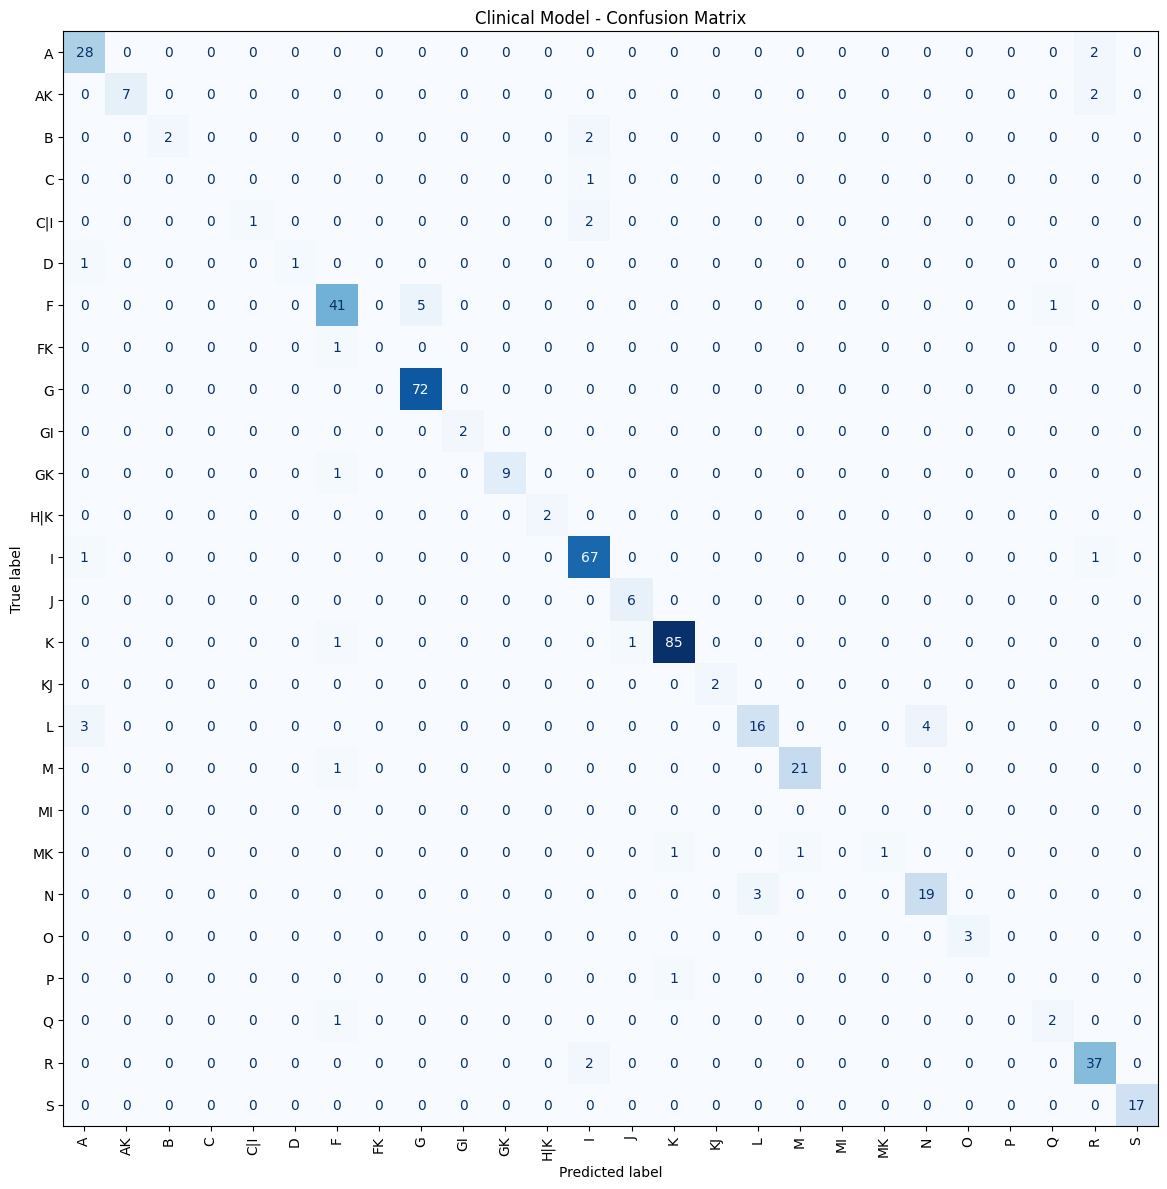

In [30]:
# ============================================================
# Step 19 - Confusion Matrix
# ============================================================

import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

# Confusion matrix
cm = confusion_matrix(
    y_test,
    y_pred,
    labels=all_labels
)

fig, ax = plt.subplots(figsize=(14, 12))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=target_encoder_clean.classes_
)

disp.plot(
    ax=ax,
    xticks_rotation=90,
    cmap="Blues",
    colorbar=False
)

plt.title("Clinical Model - Confusion Matrix")
plt.tight_layout()
plt.show()

Top 20 Important Clinical Features:


,Feature,Importance
0,numeric__FTI,0.138365
1,numeric__TSH,0.128425
2,numeric__T3,0.127114
3,numeric__TT4,0.115330
4,numeric__T4U,0.111017
5,remainder__on_thyroxine,0.060884
6,numeric__age,0.058036
7,remainder__tumor,0.028440
8,remainder__thyroid_surgery,0.028154
9,remainder__I131_treatment,0.020874


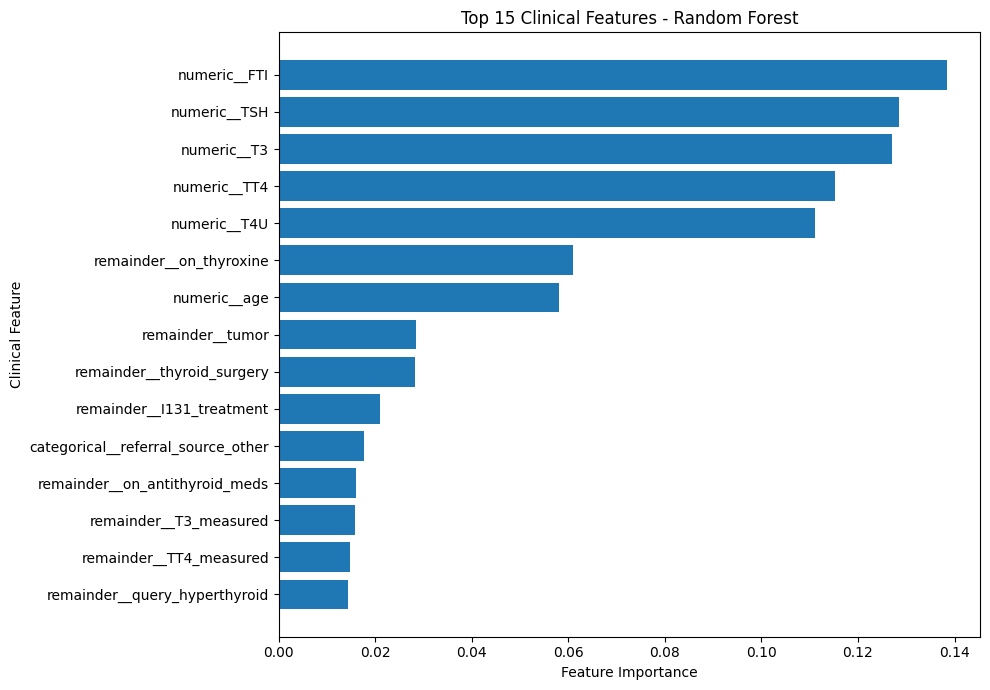

In [31]:
# ============================================================
# Step 20 - Clinical Feature Importance
# ============================================================

import pandas as pd
import matplotlib.pyplot as plt

# Get feature names after preprocessing
feature_names = clinical_preprocessor.get_feature_names_out()

# Get importance from Random Forest
importance_values = clinical_model.feature_importances_

feature_importance = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importance_values
})

# Sort from highest to lowest
feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
).reset_index(drop=True)

print("Top 20 Important Clinical Features:")
display(feature_importance.head(20))

# ------------------------------------------------------------
# Plot Top 15 Features
# ------------------------------------------------------------

top_features = feature_importance.head(15).sort_values(
    by="Importance",
    ascending=True
)

plt.figure(figsize=(10, 7))

plt.barh(
    top_features["Feature"],
    top_features["Importance"]
)

plt.xlabel("Feature Importance")
plt.ylabel("Clinical Feature")
plt.title("Top 15 Clinical Features - Random Forest")

plt.tight_layout()
plt.show()

In [32]:
# ============================================================
# Step 21 - Save Clinical Model Artifacts
# ============================================================

from pathlib import Path
import joblib
import json

# ------------------------------------------------------------
# Create clinical model directory
# ------------------------------------------------------------

CLINICAL_MODEL_DIR = (
    PROJECT_ROOT
    / "models"
    / "clinical"
)

CLINICAL_MODEL_DIR.mkdir(
    parents=True,
    exist_ok=True
)

# ------------------------------------------------------------
# File paths
# ------------------------------------------------------------

MODEL_PATH = CLINICAL_MODEL_DIR / "clinical_model.joblib"
PREPROCESSOR_PATH = CLINICAL_MODEL_DIR / "clinical_preprocessor.joblib"
TARGET_ENCODER_PATH = CLINICAL_MODEL_DIR / "target_encoder.joblib"
FEATURE_INFO_PATH = CLINICAL_MODEL_DIR / "feature_info.json"

# ------------------------------------------------------------
# Save model
# ------------------------------------------------------------

joblib.dump(
    clinical_model,
    MODEL_PATH
)

# Save preprocessing pipeline
joblib.dump(
    clinical_preprocessor,
    PREPROCESSOR_PATH
)

# Save target encoder
joblib.dump(
    target_encoder_clean,
    TARGET_ENCODER_PATH
)

# ------------------------------------------------------------
# Save feature/model metadata
# ------------------------------------------------------------

feature_metadata = {
    "model_type": "RandomForestClassifier",
    "n_estimators": 300,
    "class_weight": "balanced",
    "random_state": 42,
    "training_records": int(len(X_train_raw)),
    "testing_records": int(len(X_test_raw)),
    "number_of_classes": int(len(target_encoder_clean.classes_)),
    "number_of_processed_features": int(
        X_train_processed.shape[1]
    ),
    "classes": list(
        target_encoder_clean.classes_
    ),
    "excluded_singleton_classes": [
        "LJ",
        "GKJ",
        "OI",
        "D|R",
        "E"
    ],
    "dropped_columns": [
        "patient_id",
        "TBG"
    ],
    "metrics": {
        "accuracy": float(accuracy),
        "precision_weighted": float(precision),
        "recall_weighted": float(recall),
        "f1_weighted": float(f1)
    }
}

with open(
    FEATURE_INFO_PATH,
    "w",
    encoding="utf-8"
) as f:
    json.dump(
        feature_metadata,
        f,
        indent=4
    )

# ------------------------------------------------------------
# Verify saved files
# ------------------------------------------------------------

print("Clinical model artifacts saved successfully.\n")

for file_path in [
    MODEL_PATH,
    PREPROCESSOR_PATH,
    TARGET_ENCODER_PATH,
    FEATURE_INFO_PATH
]:
    print(
        f"{file_path.name}:",
        "OK" if file_path.exists() else "FAILED"
    )

print("\nSaved location:")
print(CLINICAL_MODEL_DIR)

Clinical model artifacts saved successfully.

clinical_model.joblib: OK
clinical_preprocessor.joblib: OK
target_encoder.joblib: OK
feature_info.json: OK

Saved location:
D:\MultiModalCancerTherapy_Structure\MultiModalCancerTherapy_Structure\models\clinical
